# Homework 4 – Evaluation Metrics for Classification

Dataset: lead scoring (`course_lead_scoring.csv`). Target variable: `converted` – whether the client signed up to the platform.

Steps follow the approach from the lecture notebook (DictVectorizer + LogisticRegression, ROC AUC, precision/recall, K-Fold CV).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

## Data preparation

In [2]:
url = 'https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,number_of_courses_viewed,annual_income,employment_status,location,interaction_count,lead_score,converted
0,paid_ads,NaN,1,79450.0,unemployed,south_america,4,0.94,1
1,social_media,retail,1,46992.0,employed,south_america,1,0.80,0
2,events,healthcare,5,78796.0,unemployed,australia,3,0.69,1
3,paid_ads,retail,2,83843.0,NaN,australia,1,0.87,0
4,referral,education,3,85012.0,self_employed,europe,3,0.62,1


In [3]:
df.isnull().sum()

lead_source                 128
industry                    134
number_of_courses_viewed      0
annual_income               181
employment_status           100
location                     63
interaction_count             0
lead_score                    0
converted                     0
dtype: int64

Fill missing values: categorical features with `'NA'`, numerical features with `0.0`.

In [4]:
target = 'converted'

numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']
categorical = [c for c in df.columns if c not in numerical and c != target]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('categorical:', categorical)
print('numerical:  ', numerical)
df.isnull().sum().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical:   ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']


np.int64(0)

Split 60% / 20% / 20% with `random_state=1`.

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

len(df_train), len(df_val), len(df_test)

(876, 293, 293)

## Question 1: ROC AUC feature importance

For each numerical variable, use it as the score on the **training** data and compute AUC. If AUC < 0.5, invert the variable (`-df_train[col]`).

In [6]:
feature_auc = {}
for col in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    feature_auc[col] = auc

pd.Series(feature_auc).sort_values(ascending=False).round(4)

number_of_courses_viewed    0.7636
interaction_count           0.7383
lead_score                  0.6145
annual_income               0.5520
dtype: float64

In [7]:
q1 = max(feature_auc, key=feature_auc.get)
print('Q1 answer:', q1)

Q1 answer: number_of_courses_viewed


## Question 2: Training the model

One-hot encode with `DictVectorizer(sparse=False)` and train `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`. Compute AUC on validation.

In [8]:
features = categorical + numerical

def train(df_train, y_train, C=1.0):
    dicts = df_train[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [9]:
dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)

val_auc = roc_auc_score(y_val, y_pred)
print('Q2 answer (validation AUC):', round(val_auc, 3))

Q2 answer (validation AUC): 0.817


## Question 3: Precision and Recall

Evaluate precision and recall on the validation set for thresholds from 0.0 to 1.0 with step 0.01, and find where the curves intersect.

In [10]:
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])
# precision is undefined when nothing is predicted positive -> leave as NaN
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp).replace(0, np.nan)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

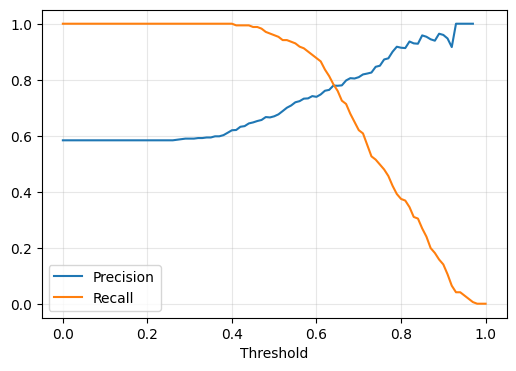

In [11]:
plt.figure(figsize=(6, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
valid = df_scores.dropna(subset=['precision'])
diff = (valid.precision - valid.recall).abs()
idx = diff.idxmin()
valid.loc[idx - 3: idx + 3, ['threshold', 'precision', 'recall']].round(3)

,threshold,precision,recall
61,0.61,0.747,0.865
62,0.62,0.761,0.836
63,0.63,0.764,0.813
64,0.64,0.779,0.784
65,0.65,0.778,0.760
66,0.66,0.780,0.725
67,0.67,0.797,0.713


In [13]:
q3 = df_scores.loc[idx, 'threshold']
print('Q3 answer (precision/recall intersect at threshold):', round(q3, 3))

Q3 answer (precision/recall intersect at threshold): 0.64


## Question 4: F1 score

F1 = 2 · P · R / (P + R). Compute it for all thresholds and find the threshold where F1 is maximal.

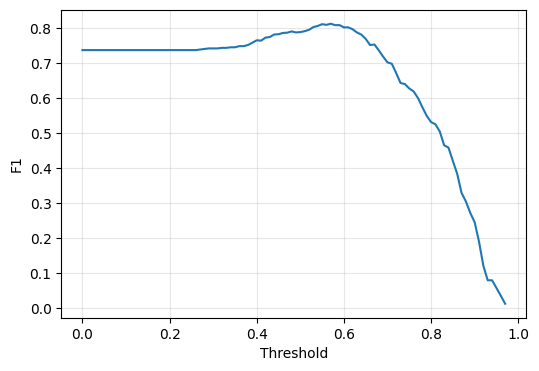

In [14]:
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)

plt.figure(figsize=(6, 4))
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('Threshold')
plt.ylabel('F1')
plt.grid(alpha=0.3)
plt.show()

In [15]:
best = df_scores.loc[df_scores.f1.idxmax()]
print('max F1 = %.3f at threshold %.2f' % (best.f1, best.threshold))
print('Q4 answer (threshold with max F1):', round(best.threshold, 2))

max F1 = 0.812 at threshold 0.57
Q4 answer (threshold with max F1): 0.57


## Question 5: 5-Fold CV

`KFold(n_splits=5, shuffle=True, random_state=1)` on the full train set (train + validation). Same model parameters as before, AUC on each validation fold.

In [16]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
cv_scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv, model = train(df_tr, df_tr[target].values, C=1.0)
    y_pred_cv = predict(df_va, dv, model)
    cv_scores.append(roc_auc_score(df_va[target].values, y_pred_cv))

print('fold AUCs:', np.round(cv_scores, 3))
print('mean = %.3f, std = %.4f' % (np.mean(cv_scores), np.std(cv_scores)))
print('Q5 answer (std):', round(np.std(cv_scores), 3))

fold AUCs: [0.806 0.871 0.775 0.802 0.856]
mean = 0.822, std = 0.0358
Q5 answer (std): 0.036


## Question 6: Hyperparameter tuning

Same 5-fold CV, trying `C` in `[0.000001, 0.001, 1]`. Report mean and std (rounded to 3 digits). Best C = highest mean (ties broken by lowest std, then smallest C).

In [17]:
results = []
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores_c = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr[target].values, C=C)
        scores_c.append(roc_auc_score(df_va[target].values, predict(df_va, dv, model)))
    mean, std = round(np.mean(scores_c), 3), round(np.std(scores_c), 3)
    results.append((C, mean, std))
    print('C=%-8s %.3f +- %.3f' % (C, mean, std))

C=1e-06    0.560 +- 0.024


C=0.001    0.867 +- 0.029


C=1        0.822 +- 0.036


In [18]:
df_res = pd.DataFrame(results, columns=['C', 'mean', 'std'])
best_C = df_res.sort_values(['mean', 'std', 'C'], ascending=[False, True, True]).iloc[0].C
print('Q6 answer (best C):', best_C)

Q6 answer (best C): 0.001


## Summary of answers

Each computed value is matched to the nearest answer option (absolute distance). For Q4 the question options can refer either to the threshold of maximum F1 or to the maximum F1 value itself, so both are shown.

In [19]:
options = {
    'Q2 Model AUC':                    [0.532, 0.632, 0.732, 0.832],
    'Q3 Precision = Recall threshold': [0.43, 0.63, 0.73, 0.83],
    'Q4 Max F1 value':                 [0.21, 0.41, 0.61, 0.81],
    'Q4 Threshold of max F1':          [0.21, 0.41, 0.61, 0.81],
    'Q5 5-Fold CV std':                [0.001, 0.007, 0.013, 0.060],
}
computed = {
    'Q2 Model AUC':                    val_auc,
    'Q3 Precision = Recall threshold': q3,
    'Q4 Max F1 value':                 best.f1,
    'Q4 Threshold of max F1':          best.threshold,
    'Q5 5-Fold CV std':                np.std(cv_scores),
}

rows = [('Q1 ROC AUC feature importance', q1, q1)]
for k, v in computed.items():
    closest = min(options[k], key=lambda o: abs(o - v))
    rows.append((k, round(v, 4), closest))
rows.append(('Q6 Best C', best_C, best_C))

pd.DataFrame(rows, columns=['Question', 'Computed', 'Closest option'])

,Question,Computed,Closest option
0,Q1 ROC AUC feature importance,number_of_courses_viewed,number_of_courses_viewed
1,Q2 Model AUC,0.8171,0.832
2,Q3 Precision = Recall threshold,0.64,0.63
3,Q4 Max F1 value,0.8125,0.81
4,Q4 Threshold of max F1,0.57,0.61
5,Q5 5-Fold CV std,0.0358,0.013
6,Q6 Best C,0.001,0.001
